In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_trips

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

trips = load_trips()
train = trips[trips["split"] == "train"]
valid = trips[trips["split"] == "valid"]

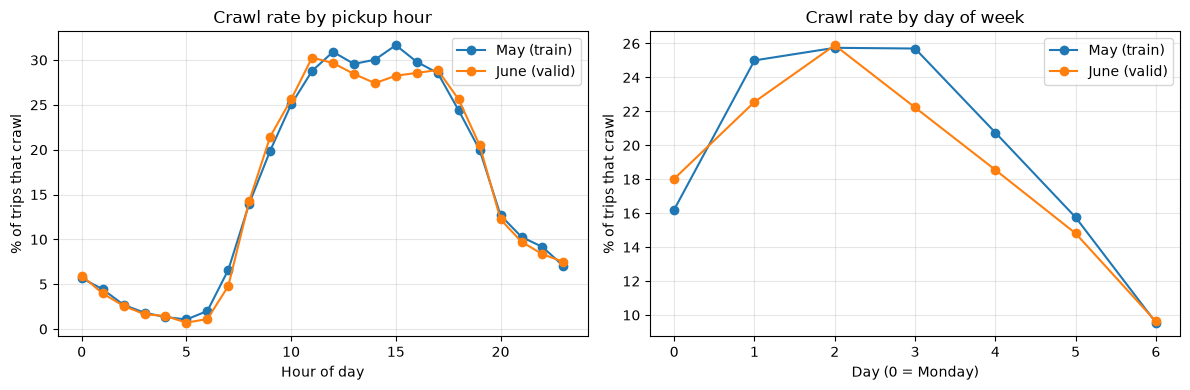

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for df, label in [(train, "May (train)"), (valid, "June (valid)")]:
    pickup = df["tpep_pickup_datetime"]
    df.groupby(pickup.dt.hour)["is_crawl"].mean().mul(100).plot(ax=axes[0], marker="o", label=label)
    df.groupby(pickup.dt.day_of_week)["is_crawl"].mean().mul(100).plot(ax=axes[1], marker="o", label=label)

axes[0].set(title="Crawl rate by pickup hour", xlabel="Hour of day", ylabel="% of trips that crawl")
axes[1].set(title="Crawl rate by day of week", xlabel="Day (0 = Monday)", ylabel="% of trips that crawl")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "crawl_rate_hour_weekday.png", dpi=150)
plt.show()

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']
EPSG:2263


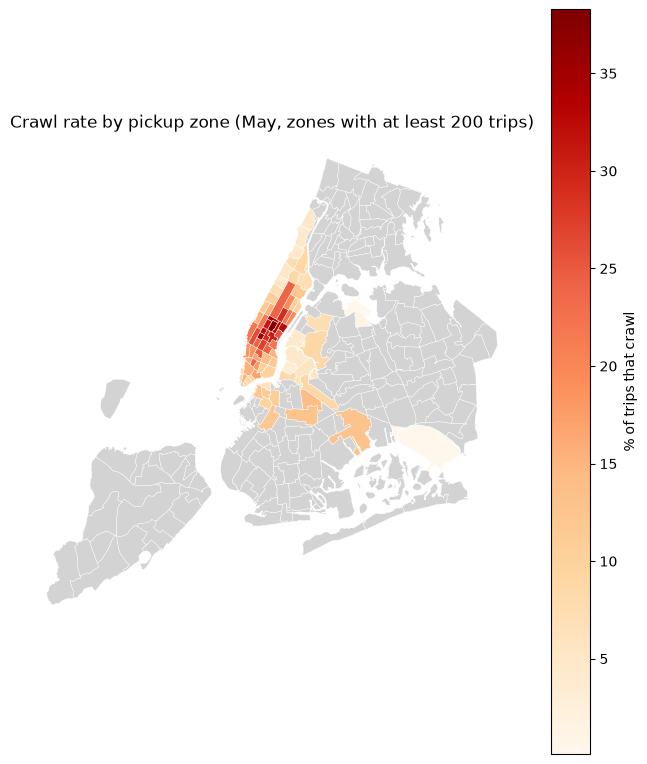

In [3]:
import geopandas as gpd

zones = gpd.read_file(ROOT / "data" / "raw" / "taxi_zones" / "taxi_zones.shp")
print(zones.columns.tolist())
print(zones.crs)

id_col = next(c for c in zones.columns if c.lower() == "locationid")

zone_stats = train.groupby("PULocationID")["is_crawl"].agg(trips="size", crawl_rate="mean")
zone_stats.loc[zone_stats["trips"] < 200, "crawl_rate"] = float("nan")
zone_stats["crawl_rate"] = zone_stats["crawl_rate"] * 100

zmap = zones.merge(zone_stats, left_on=id_col, right_index=True, how="left")

fig, ax = plt.subplots(figsize=(8, 10))
zmap.plot(
    column="crawl_rate",
    cmap="OrRd",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.3,
    missing_kwds={"color": "lightgrey"},
    legend_kwds={"label": "% of trips that crawl"},
)
ax.set_title("Crawl rate by pickup zone (May, zones with at least 200 trips)")
ax.set_axis_off()

plt.savefig(FIG_DIR / "crawl_rate_zone_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
top_zones = (
    zmap[zmap["crawl_rate"].notna()]
    [[id_col, "zone", "borough", "trips", "crawl_rate"]]
    .sort_values("crawl_rate", ascending=False)
    .head(10)
    .round({"crawl_rate": 1})
)
top_zones

,LocationID,zone,borough,trips,crawl_rate
160,161,Midtown Center,Manhattan,7746.0,38.3
185,186,Penn Station/Madison Sq West,Manhattan,5410.0,35.2
162,163,Midtown North,Manhattan,4627.0,33.1
161,162,Midtown East,Manhattan,5693.0,32.8
228,229,Sutton Place/Turtle Bay North,Manhattan,3079.0,32.2
99,100,Garment District,Manhattan,2380.0,32.1
229,230,Times Sq/Theatre District,Manhattan,5246.0,31.0
169,170,Murray Hill,Manhattan,4878.0,30.6
163,164,Midtown South,Manhattan,3501.0,29.4
236,237,Upper East Side South,Manhattan,9485.0,29.0


In [5]:
import pandas as pd
from src.data import RAW_PATH

raw = pd.read_parquet(RAW_PATH)
may = raw[raw["tpep_pickup_datetime"].dt.month == 5]
print("May raw trips:", len(may))

print("\nMissing values (%):")
print((may.isna().mean() * 100).round(2).loc[lambda s: s > 0])

print("\nNegative values (count):")
numeric = may.select_dtypes("number")
print((numeric < 0).sum().loc[lambda s: s > 0])

print("\nDuplicated rows:", may.duplicated().sum())

print("\npayment_type counts:")
print(may["payment_type"].value_counts())

print("\npassenger_count counts:")
print(may["passenger_count"].value_counts(dropna=False).head(8))

print("\nPickup == dropoff location (%):", round((may["PULocationID"] == may["DOLocationID"]).mean() * 100, 1))
print("Pickup after dropoff:", (may["tpep_dropoff_datetime"] < may["tpep_pickup_datetime"]).sum())

May raw trips: 199999

Missing values (%):
passenger_count          23.3
RatecodeID               23.3
store_and_fwd_flag       23.3
congestion_surcharge     23.3
Airport_fee              23.3
request_source          100.0
dtype: float64

Negative values (count):
fare_amount              690
extra                    366
mta_tax                  674
tolls_amount              51
improvement_surcharge    700
total_amount             711
congestion_surcharge     564
Airport_fee              113
cbd_congestion_fee       470
dtype: int64

Duplicated rows: 0

payment_type counts:
payment_type
1    133571
0     46601
2     18149
4      1108
3       570
Name: count, dtype: int64

passenger_count counts:
passenger_count
1.0    126195
NaN     46601
2.0     19306
3.0      4175
4.0      2560
0.0       622
5.0       350
6.0       190
Name: count, dtype: int64

Pickup == dropoff location (%): 4.6
Pickup after dropoff: 0
